# SOLPS plasma background → Hermes-3 grid file

**Goal:** take the converged SOLPS plasma (`SOLPS_Luciani_off/balance.nc`) as a *frozen* plasma
background for Hermes-3, so that Hermes-3 evolves **only the neutrals** on top of it.

In [1]:
%matplotlib inline
import os
import sys
import shutil

import numpy as np
import matplotlib.pyplot as plt
from boututils.datafile import DataFile

SDTOOLS = r"/Users/zero/workspace/phd_work/hms_output/sdtools"
sys.path.append(SDTOOLS)

from code_comparison.solps_pp import SOLPScase
from code_comparison.interpolate import interpolateSOLPStoHermes
from hermes3.load import Load
from hermes3.selectors import get_1d_radial_data, get_1d_poloidal_data
from hermes3.grid_fields import Mesh, Field
from hermes3.utils import constants
from hermes3.accessors import *   # registers the .hermes accessor used by the plots


%load_ext autoreload
%autoreload 2

In [2]:
ROOT = r"/Users/zero/workspace/phd_work/hms_output"

SOLPS_DIR = os.path.join(ROOT, "SOLPS_Luciani_off")                              # holds balance.nc
CASE_DIR = os.path.join(ROOT, "260717_highrsl_6e20_coreOO")                       # any run on the target grid
GRID_IN = os.path.join(ROOT, "gridfile", "CDN_46895_260513_nowallpump_6e20.nc")
GRID_OUT = os.path.join(ROOT, "gridfile", "CDN_46895_highrsl_6e20_solpsbg_260910_my_nml.nc")    


# ---------------------------------------------------------------- 2. load SOLPS (derive_data runs in __init__)
print(SOLPS_DIR)
solps = SOLPScase(SOLPS_DIR)

# Read Hermes-3 to get equilibrium data
# ---------------------------------------------------------------- 1. load the Hermes-3 case WITH guard cells
# Any converged run on the target grid works - it only supplies the mesh, geometry and the
# reference profiles for the comparison plots. Load.case_2D keeps x and y boundaries by default.
case = Load.case_2D(
    casepath=CASE_DIR,
    gridfilepath=GRID_IN,
    use_squash=True,     # writes/reuses BOUT.squash.nc - much faster than globbing BOUT.dmp.*
    unnormalise=True,    # SI units: m^-3, eV, m/s
    verbose=True,
)
case.extract_2d_tokamak_geometry()   # adds theta_idx + the metadata the selectors need

# interpolateSOLPStoHermes needs ONE time slice with dims (x, theta)
ds = case.ds.isel(t=-1)
m = ds.metadata

# Check
assert ds["Ne"].dims == ("x", "theta"), ds["Ne"].dims
print("\nshape (x, theta):", ds["Ne"].shape)
print({k: int(m[k]) for k in
       ["nx", "ny", "ny_inner", "MXG", "MYG", "ixseps1", "ixseps2",
        "jyseps1_1", "jyseps2_1", "jyseps1_2", "jyseps2_2"] if k in m})


/Users/zero/workspace/phd_work/hms_output/SOLPS_Luciani_off
- Reading case 260717_highrsl_6e20_coreOO
-----------------------
- Looking for squash file
- Squash file found. squash date 08/27/2026, 21:44:52, dmp file date 08/07/2026, 03:50:02


/Users/zero/workspace/phd_work/hms_output/xhermes/lib/python3.12/site-packages/boutdata/data.py:762: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: 'float' object cannot be interpreted as an integer
Evaluating non-scalar options not available
  alwayswarn(
/Users/zero/workspace/phd_work/hms_output/xBOUT/xbout/load.py:1294: UserWarning: Will drop all variables containing the dimensions 'closed_wall' because they are not recognised
  warn(



Unnormalising with xHermes

shape (x, theta): (40, 208)
{'nx': 40, 'ny': 200, 'ny_inner': 70, 'MXG': 2, 'MYG': 2, 'ixseps1': 20, 'ixseps2': 20, 'jyseps1_1': 19, 'jyseps2_1': 49, 'jyseps1_2': 109, 'jyseps2_2': 159}


### Check the datatset before run

##### Check radial data 
To get the distance of each ring (sepdist)

In [3]:
param = ["Ne"]
# dist = 0.001
add = 1
hermes_region = "omp"
solps_region = "omp"
# interp.plot_1d_check(ds, "Ne")
df_hermes = get_1d_radial_data(ds, params=param, region=hermes_region)
# df_hermes = get_1d_poloidal_data(ds, params=param, sepdist=dist, region=hermes_region)
print("Hermes-3 radial data ")
print(df_hermes)
print("SOLPS poloidal data:")
df_solps = solps.get_1d_radial_data(params=param, region=solps_region)
print(df_solps)


Hermes-3 radial data 
    total_poloidal_distance      zeta        dr            Ne      Srad  sep  \
2                  3.831418  3.141593  0.007483  3.648546e+18 -0.058898    0   
3                  3.943389  3.141593  0.006791  3.597172e+18 -0.051761    0   
4                  4.049806  3.141593  0.006145  3.547098e+18 -0.045293    0   
5                  4.150752  3.141593  0.005542  3.496855e+18 -0.039449    0   
6                  4.246313  3.141593  0.004980  3.447383e+18 -0.034188    0   
7                  4.336584  3.141593  0.004459  3.399347e+18 -0.029469    0   
8                  4.421685  3.141593  0.003977  3.353391e+18 -0.025251    0   
9                  4.501782  3.141593  0.003534  3.310215e+18 -0.021496    0   
10                 4.577099  3.141593  0.003131  3.270425e+18 -0.018164    0   
11                 4.647935  3.141593  0.002767  3.234059e+18 -0.015215    0   
12                 4.714687  3.141593  0.002442  3.200659e+18 -0.012611    0   
13                

In [21]:
param = ["Ne"]
# dist = 0.001
add = 1
hermes_region = "outer_lower_sol"
solps_region = "outer_lower_sol_extra"
# interp.plot_1d_check(ds, "Ne")
df_hermes = get_1d_poloidal_data(ds, params=param, sepadd=add, region=hermes_region)
# df_hermes = get_1d_poloidal_data(ds, params=param, sepdist=dist, region=hermes_region)
print("Hermes-3 poloidal data (original and interpolated):")
print(df_hermes)
print("SOLPS poloidal data:")
df_solps = solps.get_1d_poloidal_data(params=["Ne"], sepadd=add, region=solps_region, interpolate_radial=False)
# df_solps = solps.get_1d_poloidal_data(params=["Ne"], sepdist=dist, region=solps_region)
print(df_solps)

# Check the Spol length
print("Hermes Spol leg length:", df_hermes["Spol"].iloc[-1], " SOLPS Spol:", df_solps["Spol"].iloc[-1])
print("Ratio:", df_hermes["Spol"].iloc[-1] / df_solps["Spol"].iloc[-1])
print("relative diff: ", (df_hermes["Spol"].iloc[-1]-df_solps["Spol"].iloc[-1]) / df_hermes["Spol"].iloc[-1])

# Check the Spar length
print("Hermes Spar leg length:", df_hermes["Spar"].iloc[-1], " SOLPS Spar:", df_solps["Spar"].iloc[-1])
print("Ratio:", df_hermes["Spar"].iloc[-1] / df_solps["Spar"].iloc[-1])
print("relative diff: ", (df_hermes["Spar"].iloc[-1]-df_solps["Spar"].iloc[-1]) / df_hermes["Spar"].iloc[-1])

Hermes-3 poloidal data (original and interpolated):
           R         Z      dpol       Bxy      Bpxy  theta_idx            Ne  \
0   1.387879  0.000000  0.072726  0.442371  0.229761        NaN  2.919862e+18   
1   1.387879 -0.036357  0.072726  0.442371  0.229761      141.0  2.919862e+18   
2   1.380045 -0.108551  0.072497  0.448500  0.237957      142.0  2.919846e+18   
3   1.366182 -0.179498  0.072059  0.457850  0.249298      143.0  2.920621e+18   
4   1.349650 -0.249355  0.071482  0.464863  0.254923      144.0  2.923140e+18   
..       ...       ...       ...       ...       ...        ...           ...   
61  1.403424 -1.961993  0.015737  0.376182  0.041946      201.0  1.210414e+19   
62  1.417728 -1.960724  0.012946  0.372455  0.042126      202.0  1.134169e+19   
63  1.429138 -1.959349  0.009999  0.369544  0.042345      203.0  1.024074e+19   
64  1.437517 -1.958131  0.006896  0.367442  0.042551      204.0  8.999229e+18   
65  1.442734 -1.957282  0.003634  0.366149  0.042700     

In [5]:
# ------------------------------------------------- patch fpsi: b2fgmtry has it as all zeros
import scipy.interpolate
from code_comparison.interpolate import read_geqdsk

GEQDSK = os.path.join(ROOT, "46895_forward_ip.geqdsk")
print(solps.g["fpsi"])

if np.ptp(solps.g["fpsi"]) == 0:
    print("fpsi in SOLPS is zero so patching it ...")
    eq = read_geqdsk(open(GEQDSK).read())
    psi_spline = scipy.interpolate.RectBivariateSpline(eq["R1d"], eq["Z1d"], eq["psi"].T)
    solps.g["fpsi"] = psi_spline.ev(solps.g["R"], solps.g["Z"])
    print("patched fpsi from geqdsk")

f = solps.g["fpsi"]
assert f.shape == solps.g["R"].shape, (f.shape, solps.g["R"].shape)
assert np.isfinite(f).all()
print(f"fpsi range [{f.min():.5f}, {f.max():.5f}]")
for pol in (5, 50, 100, 150, 200):
    p = f[pol, 1:-1]
    assert np.all(np.diff(p) > 0) or np.all(np.diff(p) < 0), f"non-monotonic at pol {pol}"
print("fpsi monotonic radially at all sampled poloidal indices")

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
fpsi in SOLPS is zero so patching it ...
patched fpsi from geqdsk
fpsi range [-0.03639, -0.00178]
fpsi monotonic radially at all sampled poloidal indices


##### Check variables after patching fpsi in SOLPS

In [8]:
param = ["Ne"]
add = 5
# dist = 0.001
hermes_region = "outer_lower_sol"
solps_region = "outer_lower_sol_extra"
# interp.plot_1d_check(ds, "Ne")
df_hermes = get_1d_poloidal_data(ds, params=param, sepadd=add, region=hermes_region)
# df_hermes = get_1d_poloidal_data(ds, params=param, sepdist=dist, region=hermes_region)
# print("Hermes-3 poloidal data (original and interpolated):")
# print(df_hermes)
# print("SOLPS poloidal data:")
# Note that interpolation 
df_solps = solps.get_1d_poloidal_data(params=["Ne"], sepadd=add, region=solps_region, interpolate_radial=False)

# Check the Spol length
print("Hermes Spol leg length:", df_hermes["Spol"].iloc[-1], " SOLPS Spol:", df_solps["Spol"].iloc[-1])
print("Ratio:", df_hermes["Spol"].iloc[-1] / df_solps["Spol"].iloc[-1])
print(f"Relative diff: { (df_hermes["Spol"].iloc[-1]-df_solps["Spol"].iloc[-1]) / df_hermes["Spol"].iloc[-1]:.3f}")

# Check the Spar length
print("Hermes Spar leg length:", df_hermes["Spar"].iloc[-1], " SOLPS Spar:", df_solps["Spar"].iloc[-1])
print("Ratio:", df_hermes["Spar"].iloc[-1] / df_solps["Spar"].iloc[-1])
print(f"Relative diff: {(df_hermes["Spar"].iloc[-1]-df_solps["Spar"].iloc[-1]) / df_hermes["Spar"].iloc[-1]:.3f}")

Hermes Spol leg length: 2.6171711851357493  SOLPS Spol: 2.605298716139409
Ratio: 1.004557047114326
Relative diff: 0.005
Hermes Spar leg length: 14.667484135190156  SOLPS Spar: 14.583546538842468
Ratio: 1.0057556367461182
Relative diff: 0.006


## Interpolate SOLPS to Hermes-3

In [9]:
GEQDSK = os.path.join(ROOT, "46895_forward_ip.geqdsk")

# The radial interpolation in SOLPS interpolates on fpsi, so the patch cell above
# must have run. Re-running the SOLPScase cell resets fpsi back to zeros.
assert np.ptp(solps.g["fpsi"]) != 0, "fpsi is all zeros - re-run the fpsi patch cell"

REGIONS = [
    "outer_lower", "outer_upper", "inner_lower", "inner_upper",   # SOL legs
    "core",
    "inner_lower_pfr", "outer_lower_pfr", "inner_upper_pfr", "outer_upper_pfr",
]

PARAMS = ["Ne", "Te", "Td+", "Vd+"]

# REGIONS = [
#     "outer_lower"
# ]

# PARAMS = ["Ne"]
interp = interpolateSOLPStoHermes(ds, solps, equilibrium=GEQDSK)

for p in PARAMS:
    print(f"\n{'=' * 20} {p} {'=' * 20}")
    ds = interp.interpolate(
        p,
        regions=REGIONS,
        plot_lines=False,        # True -> overlays every Hermes/SOLPS field line on the grid (slow)
        plot_interp_debug=False, # True -> one 1D plot per ring (very slow, use on a single region)
    )



==================== Ne ====================
{'radial_start_region': 'omp', 'radial_subset': 'sol', 'coordinate': 'equilibrium', 'interpolate_midplane': True, 'flip': False, 'poloidal_region': 'outer_lower_sol'}
outer_lower 

radial_index: 20
sepadd: 0
sepdist: 0.000650

outer_lower_sol_extra
SOLPS data: 

           R         Z     fpsi            Ne      Spol       Spar      apar  \
0   1.385561  0.000000 -0.02222  2.952438e+18  0.000000   0.000000  0.005890   
1   1.385561 -0.036223 -0.02222  2.952495e+18  0.035904   0.069069  0.005890   
2   1.377822 -0.108164 -0.02222  2.963388e+18  0.107786   0.204490  0.005813   
3   1.364069 -0.178973 -0.02222  2.986140e+18  0.179651   0.336493  0.005701   
4   1.347574 -0.248770 -0.02222  3.002900e+18  0.251186   0.467070  0.005620   
..       ...       ...      ...           ...       ...        ...       ...   
61  1.404068 -1.974774 -0.02222  1.109997e+19  2.770954  22.033978  0.006899   
62  1.418790 -1.973293 -0.02222  1.102666e+19  2.78

### Check interpolation result
The interpolated variables wil be added into Hermes-3's `ds` and named as `[var]_interp`. 

In [10]:
param = ["Ne","Ne_interp"]
add = 1
# dist = 0.001
hermes_region = "outer_lower_sol"
solps_region = "outer_lower_sol_extra"
# interp.plot_1d_check(ds, "Ne")
df_hermes = get_1d_poloidal_data(ds, params=param, sepadd=add, region=hermes_region)
# df_hermes = get_1d_poloidal_data(ds, params=param, sepdist=dist, region=hermes_region)
print("Hermes-3 poloidal data (original and interpolated):")
# print(df_hermes)
print("SOLPS poloidal data:")
# Note that interpolation 
df_solps = solps.get_1d_poloidal_data(params=["Ne"], sepadd=add, region=solps_region, interpolate_radial=False)
# df_solps = solps.get_1d_poloidal_data(params=["Ne"], sepdist=dist, region=solps_region)
# print(df_solps)

# Check the Spol length
print("Hermes Spol leg length:", df_hermes["Spol"].iloc[-1], " SOLPS Spol:", df_solps["Spol"].iloc[-1])
print("Ratio:", df_hermes["Spol"].iloc[-1] / df_solps["Spol"].iloc[-1])
print("relative diff: ", (df_hermes["Spol"].iloc[-1]-df_solps["Spol"].iloc[-1]) / df_hermes["Spol"].iloc[-1])

# Check the Spar length
# print("Hermes Spar leg length:", df_hermes["Spar"].iloc[-1], " SOLPS Spar:", df_solps["Spar"].iloc[-1])
print("Ratio:", df_hermes["Spar"].iloc[-1] / df_solps["Spar"].iloc[-1])
print("relative diff: ", (df_hermes["Spar"].iloc[-1]-df_solps["Spar"].iloc[-1]) / df_hermes["Spar"].iloc[-1])

Hermes-3 poloidal data (original and interpolated):
SOLPS poloidal data:
Hermes Spol leg length: 2.711054448274543  SOLPS Spol: 2.69965829544393
Ratio: 1.0042213315847586
relative diff:  0.00420358685081597
Ratio: 1.0086554466292004
relative diff:  0.00858117274647737


In [ ]:
# PARAMS = ["Ne"]
for p in PARAMS:
    interp.plot_1d_check(ds, p)
    plt.suptitle(p, y=1.01, fontsize=14)

Hermes ring1 sepdist : 0.0019612032336007307
SOLPS  ring1 dist    : 0.0019719559076360887
Upstream difference [eV]: 0.0


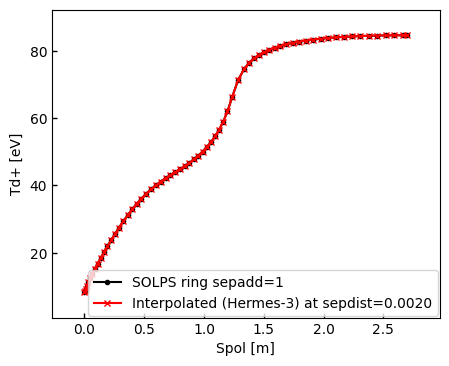

In [20]:
# Get Hermes ring 1 Radial location
rad = get_1d_radial_data(ds, params=["R"], region="omp", guards=False)
sol = rad[rad["region"] == "sol"]
sd  = sol.iloc[1]["Srad"] # the distance of first sol ring in Hermes-3
# print(sd)

print("Hermes ring1 sepdist :", sd)
srad = solps.get_1d_radial_data(["R"], region="omp", guards=False)
print("SOLPS  ring1 dist    :", srad[srad["dist"] > 0].iloc[1]["dist"])

# SOLPS its own ring 1
a = solps.get_1d_poloidal_data(params=["Td+"], sepadd=1,
                               region="outer_lower_sol_extra", interpolate_radial=False, target_first=True)
# Interpolated result ring 1 location 
b = solps.get_1d_poloidal_data(params=["Td+"], sepdist=sd,
                               region="outer_lower_sol_extra", interpolate_radial=False,
                               target_first=True)

import matplotlib.pyplot as plt
plt.plot(a["Spol"], a["Td+"], "k-o", ms=3, label="SOLPS ring sepadd=1 ")
plt.plot(b["Spol"], b["Td+"], "r-x", ms=4, label=f"Interpolated (Hermes-3) at sepdist={sd:.4f}")
plt.legend(); plt.xlabel("Spol [m]"); plt.ylabel("Td+ [eV]")

print("Upstream difference [eV]:", a["Td+"].iloc[0] - b["Td+"].iloc[0])


### To line up both solps and interpolated result

In [14]:
REGION_POL = "outer_lower_sol"
CHECK = ["Te", "Td+", "Ne"]
LOGY = {"Ne": True}

# Pick the ring either by index (MATCH_BY = "sepadd") or by distance from the
# separatrix at the midplane (MATCH_BY = "sepdist").
MATCH_BY = "sepdist"
RING = 1       # used when MATCH_BY == "sepadd"
DIST = 0.01    # [m], used when MATCH_BY == "sepdist"


def ring_kwargs(ds, region_pol, sepadd=None, sepdist=None,
                target_first=True, interpolate_midplane=True):
    """Put both codes on the SAME flux surface. Kept identical to pltool/benchmark.py.

    Hermes-3 uses its own ring index; SOLPS is radially interpolated to that
    ring's distance from the separatrix, which is how interpolateSOLPStoHermes
    matched them in the first place. Give either sepadd or sepdist.
    """
    radial_region = "omp" if "outer" in region_pol else "imp"
    rad = get_1d_radial_data(ds, params=["R"], region=radial_region, guards=False)
    sol = rad[rad["region"] == "sol"]

    if (sepadd is None) == (sepdist is None):
        raise ValueError("Give either sepadd or sepdist, not both")

    if sepdist is not None:
        # .idxmin() returns the index LABEL of the closest row, .get_loc()
        # turns that label into a position, which is what sepadd counts.
        idx = (sol["Srad"] - sepdist).abs().idxmin()
        sepadd = sol.index.get_loc(idx)

    sepdist_used = sol.iloc[sepadd]["Srad"]
    print(f"[ring] sepadd = {sepadd}, sepdist = {sepdist_used * 1e3:.2f} mm")

    hermes_kw = dict(region=region_pol, sepadd=sepadd, target_first=target_first,
                     interpolate_midplane=interpolate_midplane,
                     interpolate_radial=False)
    solps_kw = dict(region=f"{region_pol}_extra" if interpolate_midplane else region_pol,
                    sepdist=sepdist_used, target_first=target_first,
                    interpolate_midplane=interpolate_midplane,
                    interpolate_radial=True, extrapolate_radial=False)
    return hermes_kw, solps_kw, sepadd, sepdist_used


# benchmark.py runs with interpolate_midplane=True. It is False here to keep the
# figures below identical to the ones produced so far; flip it to True to
# reproduce what benchmark.py draws.
ring_arg = {MATCH_BY: DIST if MATCH_BY == "sepdist" else RING}
print(f"# ------- Matching by {MATCH_BY} = {ring_arg[MATCH_BY]}")
h_kw, s_kw, sepadd, sepdist_used = ring_kwargs(ds, REGION_POL,
                                               interpolate_midplane=False, **ring_arg)

# How far apart are the two codes' rings when they share the SAME index?
h_rad = get_1d_radial_data(ds, params=["R"], region="omp", guards=False)
h_sol = h_rad[h_rad["region"] == "sol"]
s_rad = solps.get_1d_radial_data(["R"], region="omp", guards=False)
s_sol = s_rad[s_rad["dist"] > 0]

h_Srad = h_sol.iloc[sepadd]["Srad"]
s_Srad = s_sol.iloc[sepadd]["dist"]
print(f"Hermes ring {sepadd} sepdist = {h_Srad * 1e3:8.3f} mm")
print(f"SOLPS  ring {sepadd} dist    = {s_Srad * 1e3:8.3f} mm")
print(f"Difference                   = {(h_Srad - s_Srad) * 1e3:+8.3f} mm")


# ------- Matching by sepdist = 0.01
[ring] sepadd = 6, sepdist = 9.44 mm
Hermes ring 6 sepdist =    9.436 mm
SOLPS  ring 6 dist    =    9.491 mm
Difference                   =   -0.055 mm


param     vs ring index     vs sepdist
Te               0.1008        -0.2827
Td+              0.2443        -0.6831
Ne            4.123e+15     -1.248e+16


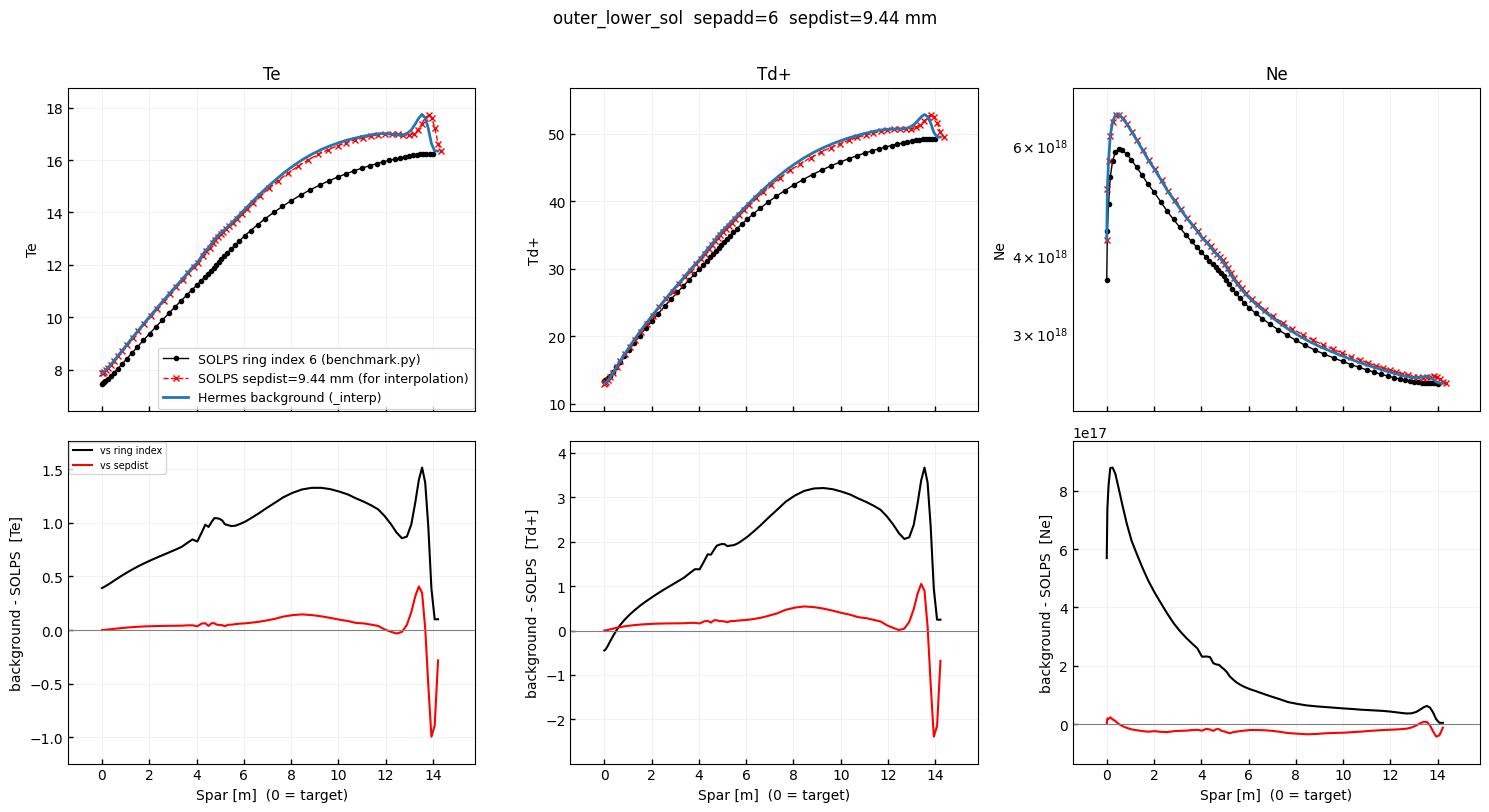

In [15]:
XC = "Spar"          # use ONE x coordinate everywhere ("Spol" or "Spar")

old_kw = dict(region=REGION_POL, sepadd=sepadd, target_first=True,
              interpolate_midplane=False, interpolate_radial=False)

fixed_pls_bg = get_1d_poloidal_data(ds, params=[f"{p}_interp" for p in CHECK], **h_kw)
s_sepadd = solps.get_1d_poloidal_data(params=CHECK, **old_kw)
s_sepdist = solps.get_1d_poloidal_data(params=CHECK, **s_kw)

fig, axes = plt.subplots(2, len(CHECK), figsize=(5 * len(CHECK), 8),
                         sharex=True, squeeze=False)

x_bg = fixed_pls_bg[XC].values

for k, p in enumerate(CHECK):
    y_bg = fixed_pls_bg[f"{p}_interp"].values

    ax = axes[0, k]
    ax.plot(s_sepadd[XC], s_sepadd[p], "o-", c="k", ms=3, lw=1,
            label=f"SOLPS ring index {sepadd} (benchmark.py)")
    ax.plot(s_sepdist[XC], s_sepdist[p], "x--", c="r", ms=4, lw=1,
            label=f"SOLPS sepdist={sepdist_used * 1e3:.2f} mm (for interpolation)")
    ax.plot(x_bg, y_bg, "-", c="tab:blue", lw=2, label="Hermes background (_interp)")
    ax.set_title(p)
    ax.set_ylabel(p)
    ax.grid(alpha=0.4)
    if LOGY.get(p):
        ax.set_yscale("log")
    if k == 0:
        ax.legend(fontsize=9)

    ax = axes[1, k]
    for df, c, lab in ((s_sepadd, "k", "vs ring index"), (s_sepdist, "r", "vs sepdist")):
        xs, ys = df[XC].values, df[p].values
        order = np.argsort(xs)
        ax.plot(x_bg, y_bg - np.interp(x_bg, xs[order], ys[order]),
                c=c, lw=1.5, label=lab)
    ax.axhline(0, c="grey", lw=0.8)
    ax.set_ylabel(f"background - SOLPS  [{p}]")
    ax.set_xlabel(f"{XC} [m]  (0 = target)")
    ax.grid(alpha=0.4)
    if k == 0:
        ax.legend(fontsize="x-small")

fig.suptitle(f"{REGION_POL}  sepadd={sepadd}  sepdist={sepdist_used * 1e3:.2f} mm", y=1.01)
fig.tight_layout()

print(f"{'param':6s} {'vs ring index':>16s} {'vs sepdist':>14s}")
for p in CHECK:
    y_bg = fixed_pls_bg[f"{p}_interp"].values
    vals = []
    for df in (s_sepadd, s_sepdist):
        xs, ys = df[XC].values, df[p].values
        order = np.argsort(xs)
        vals.append((y_bg - np.interp(x_bg, xs[order], ys[order]))[-1])
    print(f"{p:6s} {vals[0]:16.4g} {vals[1]:14.4g}")


### Fill interpolated values into new grid 

In [ ]:
fields = {
    "solps_ni": Ne,              # m^-3   -> [d+] density
    "solps_ti": Td+,              # eV     -> [d+] temperature
    "solps_vi": Vi_bg,              # m/s    -> [d+] velocity
    "solps_te": Te_bg,              # eV     -> [e]  temperature
}